# TASS projekt 1 - część B

Patryk Stachyra

In [21]:
import networkx as nx
import numpy as np
import time
from scipy.stats import linregress
from matplotlib import pyplot as plt

# wczytanie pliku
G = nx.read_edgelist("0.txt", create_using=nx.MultiGraph)

## Pierwotna sieć

In [22]:
# rząd
print(f'Rząd: {nx.number_of_nodes(G)}')

# rozmiar
print(f'Rozmiar: {nx.number_of_edges(G)}')

Rząd: 64738
Rozmiar: 258236


## Usunięcie pętli i duplikatów krawędzi

In [23]:
# usunięcie pętli
G.remove_edges_from(nx.selfloop_edges(G))

# usunięcie duplikatów - nowy graf
G_simple = nx.Graph(G)

# rząd
print(f'Rząd: {nx.number_of_nodes(G_simple)}')

# rozmiar
print(f'Rozmiar: {nx.number_of_edges(G_simple)}')

Rząd: 64738
Rozmiar: 242408


## Największa składowa wspólna

In [24]:
# wyznaczenie największej składowej wspólnej
largest_cc = max(nx.connected_components(G_simple), key=len)
GCC = G_simple.subgraph(largest_cc).copy()

# rząd
print(f'Rząd: {nx.number_of_nodes(GCC)}')

# rozmiar
print(f'Rozmiar: {nx.number_of_edges(GCC)}')

Rząd: 64268
Rozmiar: 242157


## Rozkład stopni wierzchołków i dopełnienie dystrybuanty

In [25]:
# lista stopni wierzchołków
degrees = [d for n, d in GCC.degree()]

# prawdopodobieństwo wystąpienia danego stopnia
degree_counts = np.bincount(degrees)
pdf = degree_counts / len(degrees)
k_values = np.arange(len(degree_counts))

# dopełnienie dystrybuanty
ccdf = np.array([np.sum(pdf[i:]) for i in range(len(pdf))])

## Wykres

Współczynnik rozkładu potęgowego (rozkład stopni wierzchołków): 2.911445593853442
Współczynnik rozkładu potęgowego (dopełnienie dystrybuanty): 1.911445593853442


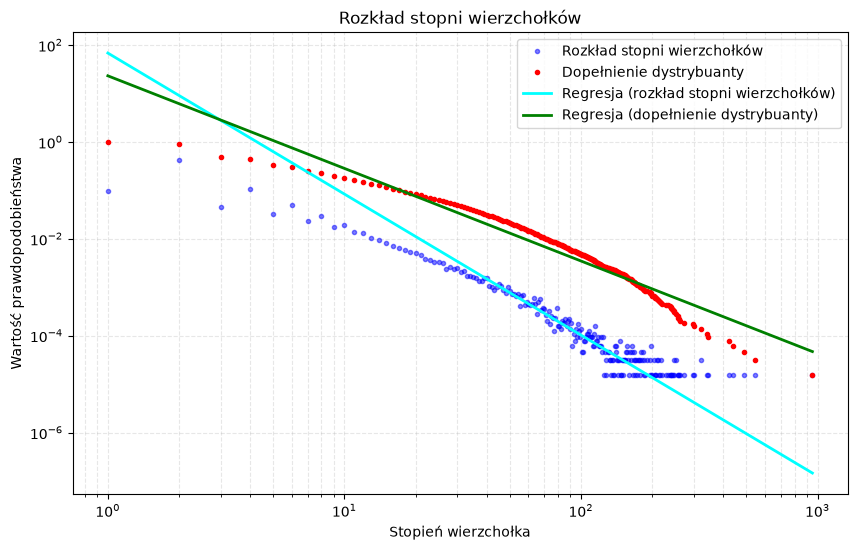

In [26]:
# odrzucenie zerowych prawdopodobieństw
valid = pdf > 0
k_valid = k_values[valid]
pdf_valid = pdf[valid]
ccdf_valid = ccdf[valid]

# logarytm
log_k = np.log10(k_valid)
log_pdf = np.log10(pdf_valid)
log_ccdf = np.log10(ccdf_valid)

# regresja liniowa
slope_ccdf, intercept_ccdf, _, _, _ = linregress(log_k, log_ccdf)
slope_pdf = slope_ccdf - 1
intercept_pdf = np.mean(log_pdf) - slope_pdf * np.mean(log_k)
print(f'Współczynnik rozkładu potęgowego (rozkład stopni wierzchołków): {abs(slope_pdf)}')
print(f'Współczynnik rozkładu potęgowego (dopełnienie dystrybuanty): {abs(slope_ccdf)}')
trend_pdf = 10 ** (slope_pdf * log_k + intercept_pdf)
trend_ccdf = 10 ** (slope_ccdf * log_k + intercept_ccdf)

# rysowanie wykresu
plt.figure(figsize=(10, 6))
plt.plot(k_valid, pdf_valid, marker='.', linestyle='none', color='blue', alpha=0.5, label='Rozkład stopni wierzchołków')
plt.plot(k_valid, ccdf_valid, marker='.', linestyle='none', color='red', label='Dopełnienie dystrybuanty')
plt.plot(k_valid, trend_pdf, color='cyan', linestyle='-', linewidth=2, label=f'Regresja (rozkład stopni wierzchołków)')
plt.plot(k_valid, trend_ccdf, color='green', linestyle='-', linewidth=2, label=f'Regresja (dopełnienie dystrybuanty)')

plt.xscale('log')
plt.yscale('log')
plt.title('Rozkład stopni wierzchołków')
plt.xlabel('Stopień wierzchołka')
plt.ylabel('Wartość prawdopodobieństwa')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.3)

plt.savefig('zad_6.png', bbox_inches='tight')
plt.show()

## Największe pośrednictwo

In [29]:
def calculate_betweenness(G, k, iterations):
    times = []
    max_nodes = []
    max_values = []

    for i in range(iterations):
        start = time.time()

        # pośrednictwo dla pojedynczej próbki
        bc = nx.betweenness_centrality(G, k)

        # węzeł o największym pośrednictwie
        max_node = max(bc, key=bc.get)
        max_value = bc[max_node]

        end = time.time()

        times.append(end - start)
        max_nodes.append(max_node)
        max_values.append(max_value)

    # statystyki
    stats_times = (np.min(times), np.mean(times), np.max(times), np.std(times))
    stats_values = (np.min(max_values), np.mean(max_values), np.max(max_values), np.std(max_values))

    return stats_times, stats_values, max_nodes

# a) 10-krotnie, dla k=100
times_a, values_a, nodes_a = calculate_betweenness(GCC, 100, 10)

# a) 100-krotnie, dla k=10
times_b, values_b, nodes_b = calculate_betweenness(GCC, 10, 100)

print('\na) k = 100, 10 iteracji')
print(f'Czas [s]: min.: {times_a[0]:.4f}, śr.: {times_a[1]:.4f}, max.: {times_a[2]:.4f}, odch. st.: {times_a[3]:.4f}')
print(f'Pośrednictwo: min.: {values_a[0]:.4f}, śr.: {values_a[1]:.4f}, max.: {values_a[2]:.4f}, odch. st.: {values_a[3]:.4f}')
print(set(nodes_a))

print('\nb) k = 10, 100 iteracji')
print(f'Czas [s]: min.: {times_b[0]:.4f}, śr.: {times_b[1]:.4f}, max.: {times_b[2]:.4f}, odch. st.: {times_b[3]:.4f}')
print(f'Pośrednictwo: min.: {values_b[0]:.4f}, śr.: {values_b[1]:.4f}, max.: {values_b[2]:.4f}, odch. st.: {values_b[3]:.4f}')
print(set(nodes_b))


a) k = 100, 10 iteracji
Czas [s]: min.: 20.5755, śr.: 21.0648, max.: 22.9843, odch. st.: 0.6835
Pośrednictwo: min.: 0.0509, śr.: 0.0675, max.: 0.0861, odch. st.: 0.0113
{'The'}

b) k = 10, 100 iteracji
Czas [s]: min.: 1.8936, śr.: 2.1330, max.: 2.4215, odch. st.: 0.1432
Pośrednictwo: min.: 0.0919, śr.: 0.1065, max.: 0.1893, odch. st.: 0.0148
{'panic', 'sweet', 'helped', 'Light', 'dog', 'Wine', 'steak', 'You', 'Dog', 'Apathy', 'penis', 'friendly', 'Larry', 'altruis', 'Evil', 'Little', 'hooray', 'Taylor', 'Shoes', 'bull', 'Crier', 'Love', 'Tax', 'Crystals', 'Pirate', 'Industrial', 'Phil', 'Opiu', 'Glorious', 'force', 'borders', 'cake', 'Strings', 'Geocaching', 'exercise', 'dentist', 'Reading', 'mystery', 'Enthusiastic', 'my', 'work', 'Religion', 'Mongol', 'Music', 'Opera', 'Free', 'Back', 'leaves', 'ball', 'Money', 'suffering', 'ronin', 'compensation', 'Queen', 'old', 'hobby', 'I', 'Language', 'Multiple', 'Fantasy', 'The', 'Everything', 'State', 'World', 'Water', 'Volcano', 'Fanboy', 'i